Dataset
Pokemon Dataset you can find here :

pokemon.csv: Contains stats like HP, Attack, Type 1, Legendary, etc., for 800+ Pokemon.
combats.csv: Records 50,000 battle outcomes between Pokemon.


What you need to do:
Data Preparation

Load and merge pokemon.csv and combats.csv.
Fix missing values:
Fill the missing Name for Pokemon #62 (Primeape).
Handle NaN values in Type 2 (mark as “None” if missing).
Calculate each Pokemon’s win percentage using the combat data.
Exploratory Analysis & Visualization

Create a correlation matrix to identify relationships between stats (HP, Attack, Speed) and win percentage.
Plot a Seaborn pairplot or PairGrid for stats vs. win percentage.
Analyze the top 10 Pokemon by win percentage and their stats.
Machine Learning

Split data into training/testing sets (80/20 split).
Train and evaluate 3 regression models (e.g., Linear Regression, Random Forest, XGBoost) to predict win percentage.
Compare model performance using Mean Absolute Error (MAE).


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

sns.set_theme(style="whitegrid")


In [4]:

# Load datasets
pokemon = pd.read_csv('/pokemon.csv')
combats = pd.read_csv('/combats.csv')

print("Pokemon shape:", pokemon.shape)
print("Combats shape:", combats.shape)

# Check missing values
print("\nMissing values:")
print(pokemon.isnull().sum())

# Fix missing Pokemon name
pokemon.loc[pokemon['#'] == 63, 'Name'] = 'Primeape'

# Fill missing secondary types
pokemon['Type 2'] = pokemon['Type 2'].fillna('None')

print("\nMissing values after cleaning:")
print(pokemon.isnull().sum())


Pokemon shape: (800, 12)
Combats shape: (50000, 3)

Missing values:
#               0
Name            1
Type 1          0
Type 2        386
HP              0
Attack          0
Defense         0
Sp. Atk         0
Sp. Def         0
Speed           0
Generation      0
Legendary       0
dtype: int64

Missing values after cleaning:
#             0
Name          0
Type 1        0
Type 2        0
HP            0
Attack        0
Defense       0
Sp. Atk       0
Sp. Def       0
Speed         0
Generation    0
Legendary     0
dtype: int64


In [5]:

# Count total battles per Pokemon
all_battles = pd.concat([
    combats['First_pokemon'],
    combats['Second_pokemon']
])

battle_counts = all_battles.value_counts().reset_index()
battle_counts.columns = ['#', 'Battles']

# Count wins per Pokemon
win_counts = combats['Winner'].value_counts().reset_index()
win_counts.columns = ['#', 'Wins']

# Merge battle statistics with Pokemon data
df = pokemon.merge(battle_counts, on='#', how='left')
df = df.merge(win_counts, on='#', how='left')

# Replace missing counts with zero
df['Battles'] = df['Battles'].fillna(0).astype(int)
df['Wins'] = df['Wins'].fillna(0).astype(int)

# Calculate win percentage
df['Win_Percentage'] = (
    df['Wins'] / df['Battles'].replace(0, np.nan)
) * 100

# Exclude Pokemon with no recorded battles
df = df.dropna(subset=['Win_Percentage']).copy()

print("Final dataset shape:", df.shape)

display(df[['Name', 'Battles', 'Wins', 'Win_Percentage']].head(10))


Final dataset shape: (784, 15)


,Name,Battles,Wins,Win_Percentage
0,Bulbasaur,133,37,27.819549
1,Ivysaur,121,46,38.016529
2,Venusaur,132,89,67.424242
3,Mega Venusaur,125,70,56.000000
4,Charmander,112,55,49.107143
5,Charmeleon,118,64,54.237288
6,Charizard,133,115,86.466165
7,Mega Charizard X,139,119,85.611511
8,Mega Charizard Y,135,114,84.444444
9,Squirtle,117,19,16.239316


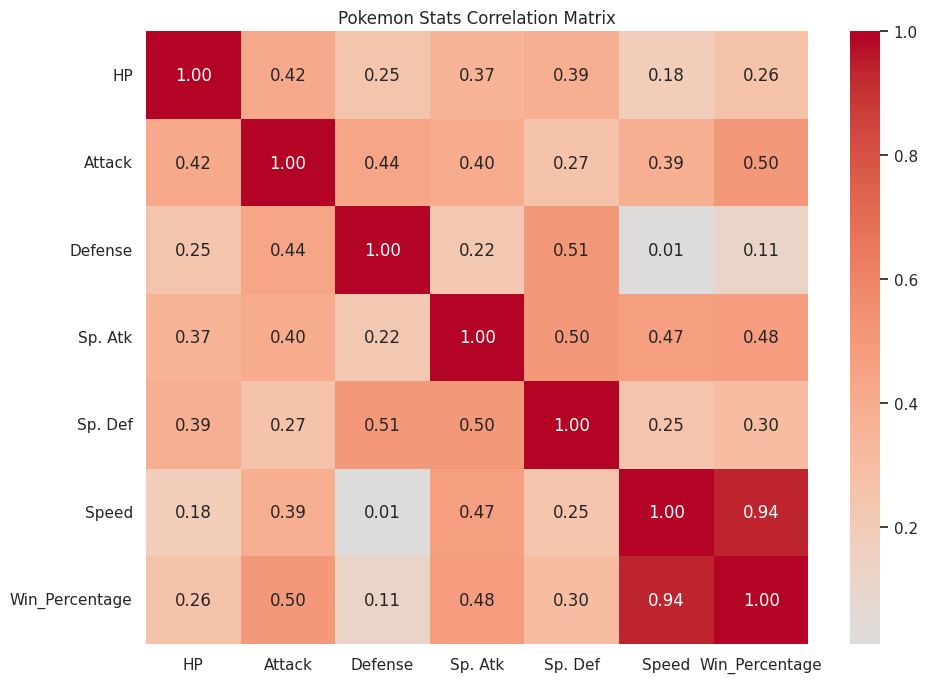

Correlations with Win Percentage:
Win_Percentage    1.000000
Speed             0.938055
Attack            0.502825
Sp. Atk           0.481445
Sp. Def           0.302422
HP                0.261602
Defense           0.114565
Name: Win_Percentage, dtype: float64


In [6]:

# Correlation Matrix

stats_columns = [
    'HP', 'Attack', 'Defense', 'Sp. Atk',
    'Sp. Def', 'Speed', 'Win_Percentage'
]

correlation_matrix = df[stats_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Pokemon Stats Correlation Matrix')
plt.tight_layout()
plt.show()

# Correlation with win percentage
print("Correlations with Win Percentage:")
print(correlation_matrix['Win_Percentage'].sort_values(ascending=False))


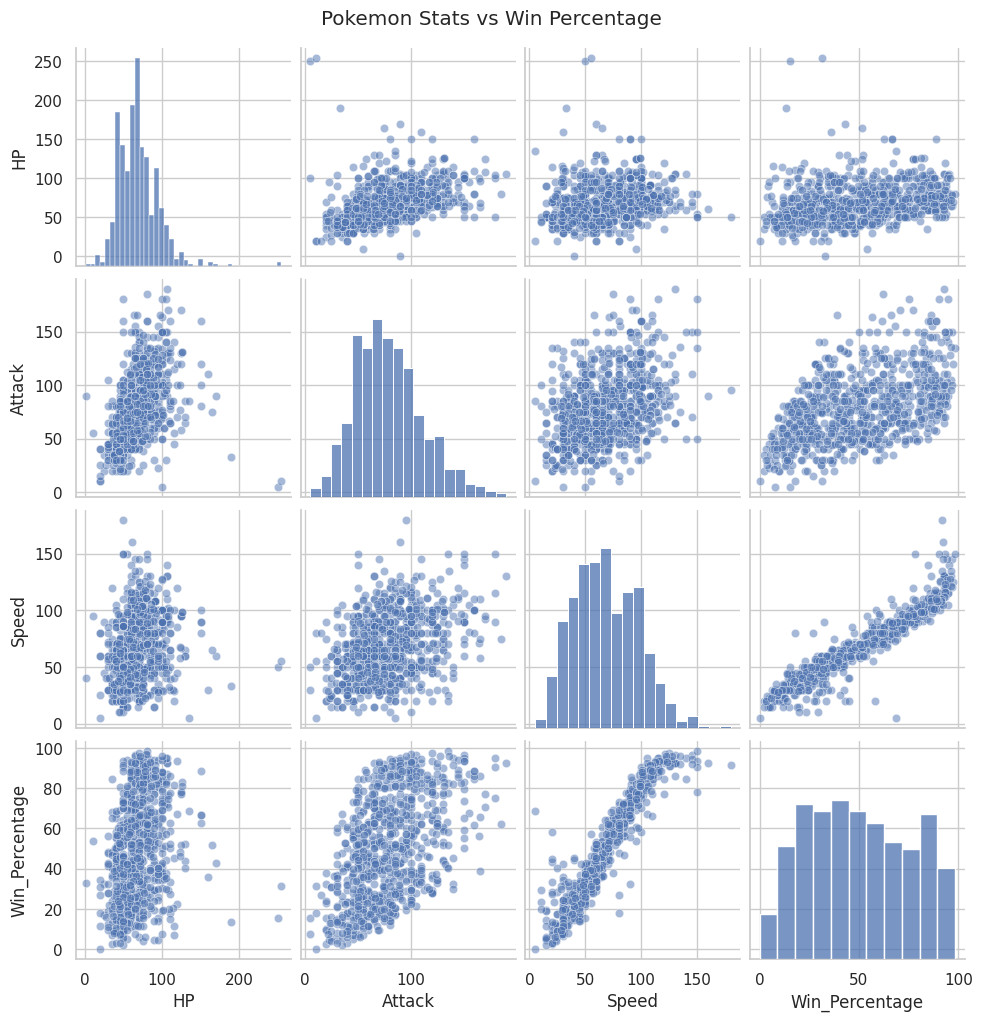

In [7]:

# Pairplot: Stats vs Win Percentage

sns.pairplot(
    df,
    vars=['HP', 'Attack', 'Speed', 'Win_Percentage'],
    diag_kind='hist',
    plot_kws={'alpha': 0.5}
)

plt.suptitle('Pokemon Stats vs Win Percentage', y=1.02)
plt.show()


,Name,Type 1,HP,Attack,Defense,Speed,Battles,Wins,Win_Percentage
154,Mega Aerodactyl,Rock,80,135,85,150,129,127,98.45
512,Weavile,Dark,70,120,65,125,119,116,97.48
703,Tornadus Therian Forme,Flying,79,100,80,121,125,121,96.80
19,Mega Beedrill,Bug,65,150,40,145,119,115,96.64
153,Aerodactyl,Rock,80,105,65,130,141,136,96.45
476,Mega Lopunny,Normal,65,136,94,135,129,124,96.12
726,Greninja,Water,72,95,67,122,127,122,96.06
716,Meloetta Pirouette Forme,Normal,100,128,90,128,123,118,95.93
164,Mega Mewtwo Y,Psychic,106,150,70,140,125,119,95.20
349,Mega Sharpedo,Water,70,140,70,105,120,114,95.00


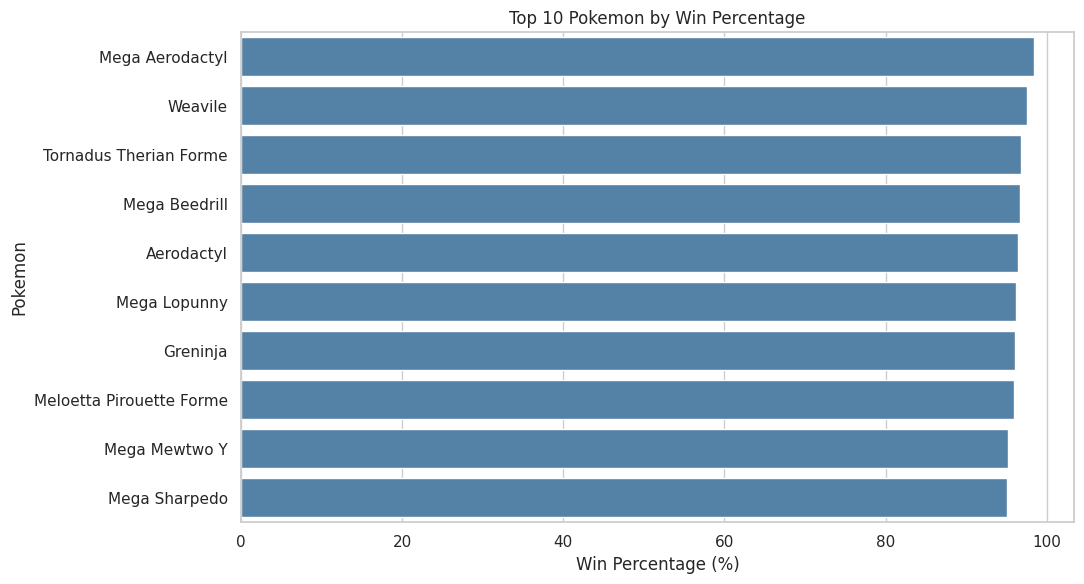

Average Speed - Top 10: 130.1
Average Speed - All Pokemon: 68.36224489795919
Average Attack - Top 10: 125.9
Average Attack - All Pokemon: 78.91964285714286


In [8]:

# Top 10 Pokemon by Win Percentage

top_10 = df.sort_values(
    by='Win_Percentage',
    ascending=False
).head(10)

display(top_10[[
    'Name', 'Type 1', 'HP', 'Attack',
    'Defense', 'Speed', 'Battles',
    'Wins', 'Win_Percentage'
]].round(2))

# Visualize Top 10
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_10,
    x='Win_Percentage',
    y='Name',
    color='steelblue'
)

plt.title('Top 10 Pokemon by Win Percentage')
plt.xlabel('Win Percentage (%)')
plt.ylabel('Pokemon')
plt.tight_layout()
plt.show()

# Compare top performers with all Pokemon
print("Average Speed - Top 10:", top_10['Speed'].mean())
print("Average Speed - All Pokemon:", df['Speed'].mean())

print("Average Attack - Top 10:", top_10['Attack'].mean())
print("Average Attack - All Pokemon:", df['Attack'].mean())


The analysis reveals a very strong positive correlation between Speed and Win Percentage (r = 0.938). Attack and Special Attack show moderate positive correlations, while Defense has a much weaker relationship with battle success.

These findings suggest that Speed is a key predictor of Pokemon battle performance in this dataset. However, correlation does not imply causation.

In [9]:

# Machine Learning - Predict Win Percentage

# Select features and target
features = [
    'HP', 'Attack', 'Defense',
    'Sp. Atk', 'Sp. Def', 'Speed',
    'Legendary'
]

X = df[features].copy()
X['Legendary'] = X['Legendary'].astype(int)

y = df['Win_Percentage']

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

# Define regression models
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(
        n_estimators=100, random_state=42
    ),
    'Gradient Boosting': GradientBoostingRegressor(
        random_state=42
    )
}

# Train and evaluate each model
results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae
    })

# Compare performance
results_df = pd.DataFrame(results).sort_values('MAE')

print("\nModel Comparison:")
display(results_df.round(4))

print("Best Model:", results_df.iloc[0]['Model'])
print("Best MAE:", round(results_df.iloc[0]['MAE'], 4))


Training set: (627, 7)
Testing set: (157, 7)

Model Comparison:


,Model,MAE
2,Gradient Boosting,4.2211
1,Random Forest,4.4735
0,Linear Regression,6.1866


Best Model: Gradient Boosting
Best MAE: 4.2211


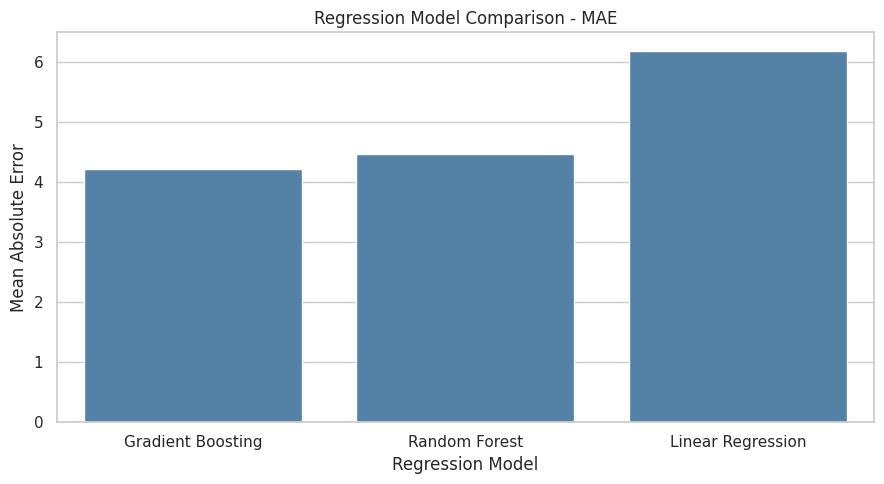

In [10]:

# Compare regression models using MAE

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='MAE',
    color='steelblue'
)

plt.title('Regression Model Comparison - MAE')
plt.xlabel('Regression Model')
plt.ylabel('Mean Absolute Error')
plt.tight_layout()
plt.show()


## Final Conclusions — Pokemon Battle Analysis

### 1. Data Preparation
The analysis combined 800 Pokemon records with 50,000 battle results. Missing values were handled, and the win percentage was calculated for each Pokemon. The final dataset included 784 Pokemon with recorded battles.

### 2. Exploratory Data Analysis
Speed showed the strongest correlation with win percentage (r = 0.938), followed by Attack (r = 0.503) and Special Attack (r = 0.481).

Mega Aerodactyl, Weavile, and Tornadus Therian Forme ranked among the top-performing Pokemon.

These findings suggest that Speed is a particularly important indicator of battle success in this dataset.

### 3. Machine Learning Results
Three regression models were trained using an 80/20 train-test split:

- Linear Regression: MAE = 6.1866
- Random Forest: MAE = 4.4735
- Gradient Boosting: MAE = 4.2211

Gradient Boosting achieved the best performance, reducing the prediction error by approximately 31.8% compared to Linear Regression.

### 4. Key Takeaways
Speed is strongly associated with Pokemon win percentage, while Attack and Special Attack also contribute useful information.

Gradient Boosting provided the most accurate predictions among the three tested